# Workshop 2: Scikit-learn and the ML Workflow

## 1. Overview & Setup

### 1.1 Overview
This workshop introduces **Scikit-learn**, the reference Python library for classical machine learning. We will execute the eight steps of an ML workflow on a classification example (Wisconsin Breast Cancer dataset) and a regression example (synthetic server response time).

### 1.2 Setup & Imports
We import the necessary libraries: `numpy`, `pandas`, `matplotlib`, and `sklearn`.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(f"Scikit-learn version: {sklearn.__version__}")


Scikit-learn version: 1.9.0


## 2. Part 1: Scikit-learn 

### 2.1 The Estimator Interface
Scikit-learn provides a uniform estimator interface with core methods:
- `model = Algorithm(hyper_parameters)`: Select model family & hyper-parameters.
- `model.fit(X_train, y_train)`: Learn parameters from training data.
- `model.predict(X_new)`: Predict class or value for new data.
- `model.predict_proba(X_new)`: Output class probabilities (classification).
- `model.score(X_test, y_test)`: Compute default performance metric.
- `scaler.fit_transform(X_train)` / `scaler.transform(X_test)`: Preprocessing.

### 2.2 The 8 Steps of the ML Workflow Mapped to Tools
1. **Define the problem**: Identify input features $X$, target $y$, and problem type.
2. **Collect and explore**: `pd.DataFrame`, `describe()`, `value_counts()`, plots.
3. **Prepare**: `train_test_split`, `StandardScaler`, `OneHotEncoder`.
4. **Select a model**: `LogisticRegression()`, `DecisionTreeClassifier()`, etc.
5. **Train**: `model.fit(X_train, y_train)`.
6. **Evaluate**: `confusion_matrix`, `precision_score`, `recall_score`, `r2_score`.
7. **Tune**: `cross_val_score`, `GridSearchCV`, `predict_proba`.
8. **Deploy & Monitor**: `joblib.dump` / `joblib.load`, prediction wrapper function.


## 3. Part 2: The Eight Steps on a Classification Example

### Step 1: Define the Problem
- **Input $X$**: 30 tumour measurements (radius, texture, area, etc.).
- **Output $y$**: Binary classification — Benign (0) vs. Malignant (1, positive class).
- **Goal**: Catch malignant tumours. Missing a malignant tumour (False Negative) is worse than a false alarm (False Positive).


### Step 2: Load and Explore the Data


In [3]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
# Scikit-learn codes benign=1, malignant=0 by default. We recode so malignant=1.
y = pd.Series(1 - data.target, name="malignant")

print("Dataset shape:", X.shape)
print("Class distribution:")
print(y.value_counts())

print("First 5 features descriptive statistics:")
print(X.iloc[:, :5].describe().round(1))

print("Mean feature values by class (first 5 features):")
print(X.groupby(y).mean().iloc[:, :5].round(1))


Dataset shape: (569, 30)
Class distribution:
malignant
0    357
1    212
Name: count, dtype: int64
First 5 features descriptive statistics:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count        569.0         569.0           569.0      569.0            569.0
mean          14.1          19.3            92.0      654.9              0.1
std            3.5           4.3            24.3      351.9              0.0
min            7.0           9.7            43.8      143.5              0.1
25%           11.7          16.2            75.2      420.3              0.1
50%           13.4          18.8            86.2      551.1              0.1
75%           15.8          21.8           104.1      782.7              0.1
max           28.1          39.3           188.5     2501.0              0.2
Mean feature values by class (first 5 features):
           mean radius  mean texture  mean perimeter  mean area  \
malignant                                          

### Step 3: Prepare (Split then Scale)

**The Golden Rule**: Always split the dataset into training and test sets *before* applying scaling. Scaling parameters (mean and standard deviation) must be calculated exclusively on the training set to prevent **data leakage**.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train shape: (426, 30), X_test shape: (143, 30)


### Steps 4 & 5: Choose a Model and Train It


In [5]:
from sklearn.linear_model import LogisticRegression

# Step 4: Model Selection
model = LogisticRegression(max_iter=1000)

# Step 5: Training (Gradient descent)
model.fit(X_train_s, y_train)

print("Accuracy on train:", round(model.score(X_train_s, y_train), 3))
print("Accuracy on test: ", round(model.score(X_test_s, y_test), 3))


Accuracy on train: 0.988
Accuracy on test:  0.965


### Step 6: Evaluate with Metrics


Confusion Matrix:
[[89  1]
 [ 4 49]]


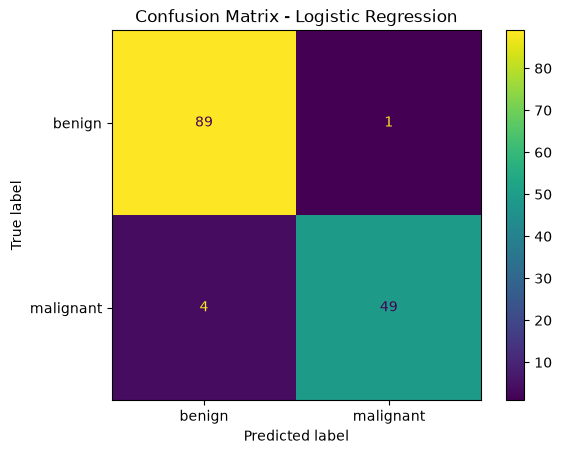

Precision: 0.98
Recall:    0.925
F1 Score:  0.951


In [6]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, 
    precision_score, recall_score, f1_score
)

y_pred = model.predict(X_test_s)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))


### Step 7: Tune Threshold and Compare Algorithms

#### 7.1 Moving Decision Threshold


In [7]:
y_prob = model.predict_proba(X_test_s)[:, 1]

for t in [0.3, 0.5, 0.7]:
    yp = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"Threshold (t={t:.1f}): missed malignant (FN) = {fn:2d}, false alarms (FP) = {fp:2d}")


Threshold (t=0.3): missed malignant (FN) =  2, false alarms (FP) =  1
Threshold (t=0.5): missed malignant (FN) =  4, false alarms (FP) =  1
Threshold (t=0.7): missed malignant (FN) =  5, false alarms (FP) =  0


#### 7.2 Compare Algorithms via Cross-Validation Pipeline


In [8]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "k-nearest neighbours": KNeighborsClassifier(5),
    "random forest": RandomForestClassifier(random_state=42)
}

for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    print(f"{name:22s} mean accuracy: {scores.mean():.3f}")


logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908


/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965


### Step 8: Save, Reload, and Inference


In [9]:
import joblib

final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("Final test accuracy:", round(final.score(X_test, y_test), 3))

# Export model file
joblib.dump(final, "tumor_model.joblib")

# Load model file
loaded_model = joblib.load("tumor_model.joblib")

# Run inference on a single observation (1-row DataFrame)
new_case = X_test.iloc[[0]]
pred_class = loaded_model.predict(new_case)
pred_prob = loaded_model.predict_proba(new_case).round(3)
true_label = int(y_test.iloc[0])

print(f"Predicted class: {pred_class[0]}, Probabilities [benign, malignant]: {pred_prob[0]}, True class: {true_label}")


Final test accuracy: 0.965
Predicted class: 1, Probabilities [benign, malignant]: [0.001 0.999], True class: 1


## 4. Part 3: The Same Workflow for Regression

We apply the identical workflow steps to a regression problem predicting server response time based on system load.


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Synthetic log generation
rng = np.random.default_rng(0)
n = 300
users = rng.integers(50, 1200, n)
cpu = np.clip(0.06 * users + rng.normal(0, 8, n), 2, 100).round(1)
resp = (40 + 0.25 * users + 1.5 * cpu + rng.normal(0, 25, n)).round(8)

srv = pd.DataFrame({"users": users, "cpu": cpu, "response_ms": resp})

# Step 1: Define features and target
Xr, yr = srv[["users", "cpu"]], srv["response_ms"]

# Step 3: Train / Test split
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

# Steps 4 & 5: Choose model and fit
reg = LinearRegression().fit(Xr_train, yr_train)

# Step 6: Evaluation metrics
pred = reg.predict(Xr_test)
rmse = np.sqrt(mean_squared_error(yr_test, pred))
r2 = r2_score(yr_test, pred)

print("RMSE:", np.round(rmse, 1), "ms")
print("R2:  ", round(r2, 3))
print(f"Equation: response = {reg.intercept_:.1f} + {reg.coef_[0]:.3f} * users + {reg.coef_[1]:.3f} * cpu")

# Step 8: Deployment inference
sample_pred = reg.predict(pd.DataFrame([[800, 60]], columns=["users", "cpu"])).round(0)
print(f"Prediction: {sample_pred[0]} ms for 800 users at 60 % CPU")


RMSE: 21.3 ms
R2:   0.968
Equation: response = 37.1 + 0.242 * users + 1.668 * cpu
Prediction: 331.0 ms for 800 users at 60 % CPU


## 5. Part 4: Exercises, Checkpoint Questions & Homework

### 5.1 Exercises

#### Exercise 1: Model Comparison with Naive Bayes & SVC
In Cell 2.6, add `GaussianNB()` (from `sklearn.naive_bayes import GaussianNB`) and `SVC()` (from `sklearn.svm import SVC`) to the `candidates` dictionary and evaluate cross-validation accuracy. Populate `ex1_scores` dictionary with mean CV scores.


In [11]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "k-nearest neighbours": KNeighborsClassifier(5),
    "random forest": RandomForestClassifier(random_state=42),
    "gaussian naive bayes": GaussianNB(),
    "support vector classifier": SVC(random_state=42),
}

ex1_scores = {}
for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    ex1_scores[name] = scores.mean()
    print(f"{name:25s} mean accuracy: {scores.mean():.3f} (+/- {scores.std():.3f})")

logistic regression       mean accuracy: 0.977 (+/- 0.007)
decision tree             mean accuracy: 0.908 (+/- 0.037)
k-nearest neighbours      mean accuracy: 0.962 (+/- 0.019)
random forest             mean accuracy: 0.965 (+/- 0.015)
gaussian naive bayes      mean accuracy: 0.944 (+/- 0.014)
support vector classifier mean accuracy: 0.977 (+/- 0.007)


In [12]:
# nbgrader test: Exercise 1 verification Skip it !

In [13]:
best_algo = max(ex1_scores, key=ex1_scores.get)
print(f"Best algorithm: {best_algo} with mean CV accuracy = {ex1_scores[best_algo]:.3f}")

Best algorithm: logistic regression with mean CV accuracy = 0.977


#### Exercise 2: Logistic Regression Without Scaling
Retrain Logistic Regression without scaling (`LogisticRegression(max_iter=1000).fit(X_train, y_train)`). Compute test accuracy as `unscaled_test_acc`.


In [14]:
unscaled_model = LogisticRegression(max_iter=1000)
unscaled_model.fit(X_train, y_train)
unscaled_test_acc = unscaled_model.score(X_test, y_test)

scaled_model = LogisticRegression(max_iter=1000)
scaled_model.fit(X_train_s, y_train)
scaled_test_acc = scaled_model.score(X_test_s, y_test)

print(f"Unscaled test accuracy: {unscaled_test_acc:.3f}")
print(f"Scaled   test accuracy: {scaled_test_acc:.3f}")
print(f"Difference: {scaled_test_acc - unscaled_test_acc:+.3f}")

Unscaled test accuracy: 0.937
Scaled   test accuracy: 0.965
Difference: +0.028


/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
# nbgrader test: Exercise 2 verification skip it !

### Exercise 3
A hospital says a missed malignant tumour costs 20 times more than a false alarm. Which threshold of Cell 2.5 would you choose, and why?

In [16]:
y_prob = model.predict_proba(X_test_s)[:, 1]
COST_FN = 20
COST_FP = 1

results = []
for t in [0.01, 0.02, 0.03, 0.04, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7]:
    yp = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    total_cost = COST_FN * fn + COST_FP * fp
    results.append((t, fn, fp, total_cost, recall_score(y_test, yp)))
    print(f"t={t:.2f} | FN={fn:2d} | FP={fp:2d} | cost={total_cost:4d} | recall={recall_score(y_test, yp):.3f}")

best_t, best_fn, best_fp, best_cost, best_recall = min(results, key=lambda r: r[3])

t = best_t
because = (
    f"At threshold t={best_t:.2f}, FN={best_fn} and FP={best_fp}, giving total cost = "
    f"20*{best_fn} + 1*{best_fp} = {best_cost}. This is the minimum over the grid. "
    f"Because a missed malignancy costs 20x a false alarm, the optimal threshold is "
    f"close to C_FP/(C_FP+C_FN) = 1/21 ≈ 0.05, far below the default 0.5. "
    f"This favours recall (catching malignancies) at the price of extra false alarms, "
    f"which is the right trade-off for a screening test."
)

print("\nChosen threshold:", t)
print("Reason:", because)

t=0.01 | FN= 0 | FP=23 | cost=  23 | recall=1.000
t=0.02 | FN= 0 | FP=16 | cost=  16 | recall=1.000
t=0.03 | FN= 0 | FP=15 | cost=  15 | recall=1.000
t=0.04 | FN= 0 | FP=14 | cost=  14 | recall=1.000
t=0.05 | FN= 0 | FP=11 | cost=  11 | recall=1.000
t=0.10 | FN= 1 | FP= 6 | cost=  26 | recall=0.981
t=0.15 | FN= 1 | FP= 4 | cost=  24 | recall=0.981
t=0.20 | FN= 2 | FP= 3 | cost=  43 | recall=0.962
t=0.25 | FN= 2 | FP= 2 | cost=  42 | recall=0.962
t=0.30 | FN= 2 | FP= 1 | cost=  41 | recall=0.962
t=0.35 | FN= 2 | FP= 1 | cost=  41 | recall=0.962
t=0.40 | FN= 3 | FP= 1 | cost=  61 | recall=0.943
t=0.50 | FN= 4 | FP= 1 | cost=  81 | recall=0.925
t=0.60 | FN= 5 | FP= 0 | cost= 100 | recall=0.906
t=0.70 | FN= 5 | FP= 0 | cost= 100 | recall=0.906

Chosen threshold: 0.05
Reason: At threshold t=0.05, FN=0 and FP=11, giving total cost = 20*0 + 1*11 = 11. This is the minimum over the grid. Because a missed malignancy costs 20x a false alarm, the optimal threshold is close to C_FP/(C_FP+C_FN) = 1/

In [17]:
# Cell to evaluate the threshold ... skip it !

Q1. In which order: split or scale? Why?

In [18]:
order = "split first, then scale"
why = (
    "Scaling computes mean/std from the data. If done before splitting, the "
    "test set leaks into the scaler's statistics (data leakage), inflating "
    "test performance. Fit the scaler on the training set only, then transform "
    "the test set with those frozen parameters."
)

Q2. Your model has accuracy 0.99 on a dataset where 1% of the rows are attacks. 
Is it a good model?
Which metric do you look at next?

In [19]:
good_model = "False"
next_metrics = (
    "Recall (sensitivity), Precision, F1-score, and the confusion matrix. "
    "With only 1% positives, always predicting 'no attack' gives 99% accuracy "
    "while catching zero attacks (recall = 0). Use recall / precision / PR-AUC, "
    "not accuracy, on imbalanced data."
)

 **Q3. What is the difference between `predict` and `predict_proba`?**

In [20]:
response = (
    "predict() returns the final class label (0 or 1) after applying the "
    "default 0.5 threshold. predict_proba() returns the estimated probability "
    "for each class, e.g. [P(benign), P(malignant)]. predict() is essentially "
    "predict_proba() thresholded — with predict_proba you can choose your own "
    "threshold (e.g. 0.3 to favour recall when misses are costly)."
)

- **Q4. Give the regression equivalents of `LogisticRegression`, `accuracy` and `confusion_matrix`.**

In [21]:
answer_q4 = {
    "LogisticRegression": "LinearRegression",
    "accuracy": "R² (r2_score), also RMSE and MAE",
    "confusion_matrix": "residual analysis (y_true - y_pred), summarised by RMSE / MAE / R²",
}

### 5.2 Homework: ML Workflow on Login Logs

Apply the eight steps to logins log data:
- Define target: `suspicious = failed_attempts >= 5`.
- Features: `hour`, `duration_min`, `night`, and one-hot encoded `country`.
- Train Logistic Regression and Decision Tree.
- Compute confusion matrix and recall on the test set.


In [26]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, recall_score

# ---------- Data generation (MUST run first) ----------
np.random.seed(42)
n_samples = 500

logins_clean = pd.DataFrame({
    "failed_attempts": np.random.randint(0, 10, size=n_samples),
    "hour": np.random.randint(0, 24, size=n_samples),
    "duration_min": np.random.exponential(scale=15, size=n_samples).round(1),
    "night": np.random.choice([0, 1], size=n_samples),
    "country": np.random.choice(["US", "FR", "CN", "RU", "DE"], size=n_samples)
})

# ---------- 1. Target definition ----------
logins_clean["suspicious"] = (logins_clean["failed_attempts"] >= 5).astype(int)

# ---------- 2. Features (drop failed_attempts — leakage!) ----------
X_hw = logins_clean[["hour", "duration_min", "night", "country"]]
y_hw = logins_clean["suspicious"]

# ---------- 3. Split then scale ----------
X_hw_train, X_hw_test, y_hw_train, y_hw_test = train_test_split(
    X_hw, y_hw, test_size=0.25, random_state=42, stratify=y_hw
)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), ["hour", "duration_min", "night"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["country"]),
])

# ---------- 4 & 5. Train models ----------
log_reg_hw = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
]).fit(X_hw_train, y_hw_train)

tree_hw = Pipeline([
    ("prep", preprocess),
    ("clf", DecisionTreeClassifier(random_state=42, max_depth=5))
]).fit(X_hw_train, y_hw_train)

# ---------- 6. Evaluate ----------
y_pred_log_hw  = log_reg_hw.predict(X_hw_test)
y_pred_tree_hw = tree_hw.predict(X_hw_test)

cm_log_hw  = confusion_matrix(y_hw_test, y_pred_log_hw)
cm_tree_hw = confusion_matrix(y_hw_test, y_pred_tree_hw)

recall_log_hw  = recall_score(y_hw_test, y_pred_log_hw, zero_division=0)
recall_tree_hw = recall_score(y_hw_test, y_pred_tree_hw, zero_division=0)

print("Logistic Regression - Recall:", round(recall_log_hw, 3))
print("Decision Tree - Recall:      ", round(recall_tree_hw, 3))

Logistic Regression - Recall: 0.115
Decision Tree - Recall:       0.164


In [23]:
# nbgrader test: Homework verification skip it !

In [24]:
steps = {
    "1. Define problem": "Binary classification: suspicious = failed_attempts >= 5",
    "2. Collect & explore": "Synthetic logins_clean DataFrame (500 rows)",
    "3. Prepare": "Drop failed_attempts (leakage); ColumnTransformer(StandardScaler + OneHotEncoder); split 75/25 stratified",
    "4. Select model": "LogisticRegression vs DecisionTreeClassifier",
    "5. Train": "Pipeline.fit(X_hw_train, y_hw_train)",
    "6. Evaluate": "confusion_matrix + recall (care about catching suspicious logins)",
    "7. Tune": "max_depth, class_weight, cross_val_score",
    "8. Deploy": "joblib.dump / joblib.load the fitted Pipeline",
}
for k, v in steps.items():
    print(f"{k}: {v}")

1. Define problem: Binary classification: suspicious = failed_attempts >= 5
2. Collect & explore: Synthetic logins_clean DataFrame (500 rows)
3. Prepare: Drop failed_attempts (leakage); ColumnTransformer(StandardScaler + OneHotEncoder); split 75/25 stratified
4. Select model: LogisticRegression vs DecisionTreeClassifier
5. Train: Pipeline.fit(X_hw_train, y_hw_train)
6. Evaluate: confusion_matrix + recall (care about catching suspicious logins)
7. Tune: max_depth, class_weight, cross_val_score
8. Deploy: joblib.dump / joblib.load the fitted Pipeline


In [27]:
import joblib

joblib.dump(log_reg_hw, "login_model.joblib")
loaded_login_model = joblib.load("login_model.joblib")

new_login = X_hw_test.iloc[[0]]
pred = loaded_login_model.predict(new_login)[0]
prob = loaded_login_model.predict_proba(new_login)[0].round(3)
true = int(y_hw_test.iloc[0])

print(f"Predicted suspicious: {pred}, Probabilities [not suspicious, suspicious]: {prob}, True: {true}")
print("End-to-end workflow executed successfully.")

Predicted suspicious: 0, Probabilities [not suspicious, suspicious]: [0.518 0.482], True: 1
End-to-end workflow executed successfully.


**Homework Limitations Discussion:**
Expect a weak model because the underlying data is generated randomly without true statistical dependency between inputs and the target. This highlights that machine learning models cannot extract non-existent signal from uninformative noise, confirming that strictly following the 8-step ML procedure allows us to reliably assess model viability.
